In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 474.4 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 5.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 11.9 MB/s eta 0:00:00


In [ ]:
#original

import os
import subprocess

video_dir = "/content/drive/MyDrive/Drone/input_video"
frames_root = "/content/drive/MyDrive/Drone/frames"

fps = 5

for filename in os.listdir(video_dir):
    if filename.lower().endswith(".mp4"):
        video_path = os.path.join(video_dir, filename)

        video_name = os.path.splitext(filename)[0]
        output_folder = os.path.join(frames_root, video_name)
        os.makedirs(output_folder, exist_ok=True)

        output_pattern = os.path.join(output_folder, "frame_%04d.jpg")

        cmd = [
            "ffmpeg",
            "-i", video_path,
            "-vf", f"fps={fps}",
            output_pattern
        ]

        print(f"Processing: {filename}")
        subprocess.run(cmd)

Processing: drone_video_2.mp4
Processing: drone_video_1.mp4


In [ ]:

import os
import shutil
from pathlib import Path

# Exact paths from your data.yaml files
drone_root = Path("/content/drive/MyDrive/Drone")
bird_root = Path("/content/drive/MyDrive/Drone/bird_dataset")

# New combined dataset
combined_root = Path("/content/drive/MyDrive/Drone/combined_dataset")

splits = ["train", "valid", "test"]

for split in splits:
    (combined_root / split / "images").mkdir(
        parents=True, exist_ok=True
    )
    (combined_root / split / "labels").mkdir(
        parents=True, exist_ok=True
    )

def combine_dataset(source_root, prefix, new_class_id):
    for split in splits:
        image_dir = source_root / split / "images"
        label_dir = source_root / split / "labels"

        if not image_dir.exists():
            raise FileNotFoundError(image_dir)
        if not label_dir.exists():
            raise FileNotFoundError(label_dir)

        count = 0

        for image_path in sorted(image_dir.iterdir()):
            if image_path.suffix.lower() not in (
                ".jpg", ".jpeg", ".png"
            ):
                continue

            # Prefix prevents filename collisions
            new_stem = f"{prefix}_{image_path.stem}"
            new_image = (
                combined_root / split / "images" /
                f"{new_stem}{image_path.suffix}"
            )
            new_label = (
                combined_root / split / "labels" /
                f"{new_stem}.txt"
            )

            shutil.copy2(image_path, new_image)

            original_label = (
                label_dir / f"{image_path.stem}.txt"
            )

            converted_lines = []

            if original_label.exists():
                with open(original_label) as f:
                    for line in f:
                        parts = line.strip().split()

                        if not parts:
                            continue

                        # Both original datasets use class 0
                        if parts[0] != "0":
                            raise ValueError(
                                f"Unexpected class in {original_label}"
                            )

                        # Drone -> 0, Bird -> 1
                        parts[0] = str(new_class_id)
                        converted_lines.append(" ".join(parts))

            with open(new_label, "w") as f:
                if converted_lines:
                    f.write("\n".join(converted_lines) + "\n")

            count += 1

        print(f"{prefix} {split}: {count} images")

# Keep drones as class 0
combine_dataset(
    drone_root,
    prefix="drone",
    new_class_id=0
)

# Convert birds to class 1
combine_dataset(
    bird_root,
    prefix="bird",
    new_class_id=1
)

print("\nCombined dataset created:", combined_root)


drone train: 694 images
drone valid: 139 images
drone test: 94 images
bird train: 281 images
bird valid: 81 images
bird test: 45 images

Combined dataset created: /content/drive/MyDrive/Drone/combined_dataset


In [ ]:
import os
import subprocess

input_video = "/content/drive/MyDrive/Drone/input_video/drone_video_1.mp4"
output_folder = "/content/drive/MyDrive/Drone/frames/video_1"

os.makedirs(output_folder, exist_ok=True)

subprocess.run([
    "ffmpeg",
    "-y",
    "-i", input_video,
    "-vsync", "0",
    os.path.join(output_folder, "frame_%06d.png")
], check=True)

print("Frames extracted successfully!")

Frames extracted successfully!


In [ ]:
import os
import subprocess

input_video = "/content/drive/MyDrive/Drone/input_video/Drone_and_Bird_New_video.mp4"
output_folder = "/content/drive/MyDrive/Drone/frames/video_drone_bird"

os.makedirs(output_folder, exist_ok=True)

subprocess.run([
    "ffmpeg",
    "-y",
    "-i", input_video,
    "-vsync", "0",
    os.path.join(output_folder, "frame_%06d.png")
], check=True)

print("Frames extracted successfully!")

Frames extracted successfully!


In [ ]:
from ultralytics import YOLO

# model = YOLO("yolo26n.pt")
# model = YOLO("/content/drive/MyDrive/Drone/yolov26n_drone_set/weights/best.pt")
#model = YOLO("/content/drive/MyDrive/Drone/yolov26n_drone_set-2/weights/best.pt")
model = YOLO("/content/drive/MyDrive/Drone/yolov26n_drone_bird-9/weights/best.pt")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


In [ ]:
results = model.train(
    data="/content/drive/MyDrive/Drone/data.yaml",
    epochs=20,
    imgsz=640,
    project="/content/drive/MyDrive/Drone",
    name="yolov26n_drone_set",
)

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA A100-SXM4-80GB, 81153MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/Drone/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov26n_drone_set, nbs=64, nms=None, 

In [ ]:
import yaml

yaml_path = "/content/drive/MyDrive/Drone/combined_dataset/data.yaml"

combined_yaml = {
    "path": "/content/drive/MyDrive/Drone/combined_dataset",
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "nc": 2,
    "names": ["drone", "bird"]
}

with open(yaml_path, "w") as f:
    yaml.safe_dump(combined_yaml, f, sort_keys=False)

print("Corrected data.yaml successfully!")

Corrected data.yaml successfully!


In [ ]:
from ultralytics import YOLO

model = YOLO("yolo26n.pt")

results = model.train(
    data="/content/drive/MyDrive/Drone/combined_dataset/data.yaml",
    epochs=50,
    imgsz=640,
    project="/content/drive/MyDrive/Drone",
    name="yolov26n_drone_bird",
)

Ultralytics 8.4.178 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA A100-SXM4-80GB, 81153MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/Drone/combined_dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov26n_drone_bird-9

In [ ]:
with open("/content/drive/MyDrive/Drone/combined_dataset/data.yaml", "r") as f:
    print(f.read())

import yaml

combined_yaml = {
    "path": "/content/drive/MyDrive/Drone/combined_dataset",
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "nc": 2,
    "names": ["drone", "bird"]
}

yaml_path = combined_root / "data.yaml"

with open(yaml_path, "w") as f:
    yaml.safe_dump(
        combined_yaml,
        f,
        sort_keys=False
    )

print("Combined data.yaml saved:", yaml_path)



In [ ]:
#original

import os
import cv2
import pandas as pd

frames_root = "/content/drive/MyDrive/Drone/frames"
output_folder = "/content/drive/MyDrive/Drone/detections"
os.makedirs(output_folder, exist_ok=True)

detections_data = []

frame_dirs = sorted([
    d for d in os.listdir(frames_root)
    if os.path.isdir(os.path.join(frames_root, d))
])

for video_id, frame_dir_name in enumerate(frame_dirs, start=1):
    frame_dir_path = os.path.join(frames_root, frame_dir_name)

    print(f"Processing video_id={video_id}, frames folder={frame_dir_name}")

    results = model.predict(
        source=frame_dir_path,
        save=False,
        stream=True,
        conf=0.15
    )

    for i, res in enumerate(results):
        if len(res.boxes) > 0:
            annotated_frame = res.orig_img.copy()
            filename = f"{frame_dir_name}_frame_{i:04d}.jpg"
            filepath = os.path.join(output_folder, filename)

            for box in res.boxes:
                class_index = int(box.cls[0])
                class_label = model.names[class_index]
                confidence = float(box.conf[0])
                coords = [int(c) for c in box.xyxy[0].tolist()]

                cv2.rectangle(
                    annotated_frame,
                    (coords[0], coords[1]),
                    (coords[2], coords[3]),
                    (0, 0, 255),
                    2
                )

                label = f"{class_label} {confidence:.2f}"
                cv2.putText(
                    annotated_frame,
                    label,
                    (coords[0], max(coords[1] - 10, 20)),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.5,
                    (0, 0, 255),
                    2
                )

                detections_data.append({
                    "video_id": video_id,
                    "frame_directory": frame_dir_name,
                    "frame_index": i,
                    "file_name": filename,
                    "file_path": filepath,
                    "class_label": class_label,
                    "bounding_box": coords,
                    "confidence_score": confidence
                })

            cv2.imwrite(filepath, annotated_frame)

df = pd.DataFrame(detections_data)
if not df.empty:
    df['center_x'] = df['bounding_box'].apply(lambda b: (b[0] + b[2]) / 2)
    df['center_y'] = df['bounding_box'].apply(lambda b: (b[1] + b[3]) / 2)

Processing video_id=1, frames folder=drone_video_1

image 1/828 /content/drive/MyDrive/Drone/frames/drone_video_1/frame_0001.jpg: 384x640 1 drone, 11.0ms
image 2/828 /content/drive/MyDrive/Drone/frames/drone_video_1/frame_0002.jpg: 384x640 1 drone, 1004.5ms
image 3/828 /content/drive/MyDrive/Drone/frames/drone_video_1/frame_0003.jpg: 384x640 1 drone, 913.6ms
image 4/828 /content/drive/MyDrive/Drone/frames/drone_video_1/frame_0004.jpg: 384x640 1 drone, 1053.3ms
image 5/828 /content/drive/MyDrive/Drone/frames/drone_video_1/frame_0005.jpg: 384x640 1 drone, 871.3ms
image 6/828 /content/drive/MyDrive/Drone/frames/drone_video_1/frame_0006.jpg: 384x640 1 drone, 851.5ms
image 7/828 /content/drive/MyDrive/Drone/frames/drone_video_1/frame_0007.jpg: 384x640 1 drone, 835.4ms
image 8/828 /content/drive/MyDrive/Drone/frames/drone_video_1/frame_0008.jpg: 384x640 1 drone, 2725.6ms
image 9/828 /content/drive/MyDrive/Drone/frames/drone_video_1/frame_0009.jpg: 384x640 1 drone, 11.7ms
image 10/828 /conten

In [ ]:
#Original video
import os
import cv2
import pandas as pd

frames_root = "/content/drive/MyDrive/Drone/frames/video_1"
output_folder = "/content/drive/MyDrive/Drone/detections"
os.makedirs(output_folder, exist_ok=True)

detections_data = []

video_id = 1
frame_dir_name = "video_1"

# Get all PNG and JPG frames in the folder
frame_files = sorted([
    f for f in os.listdir(frames_root)
    if f.lower().endswith((".png", ".jpg", ".jpeg"))
])

print(f"Processing video_id={video_id}, frames folder={frame_dir_name}")
print(f"Total frames: {len(frame_files)}")

# Run YOLO detection on each frame
for i, frame_name in enumerate(frame_files):
    frame_path = os.path.join(frames_root, frame_name)

    results = model.predict(
        source=frame_path,
        save=False,
        conf=0.15,
        verbose=False
    )

    for res in results:
        if len(res.boxes) > 0:
            annotated_frame = res.orig_img.copy()

            filename = f"{frame_dir_name}_frame_{i:04d}.png"
            filepath = os.path.join(output_folder, filename)

            for box in res.boxes:
                class_index = int(box.cls[0])
                class_label = model.names[class_index]
                confidence = float(box.conf[0])
                coords = [int(c) for c in box.xyxy[0].tolist()]

                cv2.rectangle(
                    annotated_frame,
                    (coords[0], coords[1]),
                    (coords[2], coords[3]),
                    (0, 0, 255),
                    2
                )

                label = f"{class_label} {confidence:.2f}"

                cv2.putText(
                    annotated_frame,
                    label,
                    (coords[0], max(coords[1] - 10, 20)),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.5,
                    (0, 0, 255),
                    2
                )

                detections_data.append({
                    "video_id": video_id,
                    "frame_directory": frame_dir_name,
                    "frame_index": i,
                    "file_name": filename,
                    "file_path": filepath,
                    "class_label": class_label,
                    "bounding_box": coords,
                    "confidence_score": confidence
                })

            cv2.imwrite(filepath, annotated_frame)

df = pd.DataFrame(detections_data)

if not df.empty:
    df["center_x"] = df["bounding_box"].apply(
        lambda b: (b[0] + b[2]) / 2
    )
    df["center_y"] = df["bounding_box"].apply(
        lambda b: (b[1] + b[3]) / 2
    )

print(f"Total detections: {len(df)}")
print(f"Annotated frames saved to: {output_folder}")
# Save all YOLO detection data to Google Drive
detections_csv = "/content/drive/MyDrive/Drone/detections_video_1.csv"

df.to_csv(detections_csv, index=False)

print(f"Detection data saved to: {detections_csv}")


Processing video_id=1, frames folder=video_1
Total frames: 4941
Total detections: 3113
Annotated frames saved to: /content/drive/MyDrive/Drone/detections
Detection data saved to: /content/drive/MyDrive/Drone/detections_video_1.csv


In [ ]:
import numpy as np
from sklearn.cluster import DBSCAN

def group_bird_detections(
    detections,
    flock_distance=100,
    min_birds=3
):
    """
    Input: YOLO detections for one frame.
    Output: drones, individual birds, and flocks.
    """

    drones = [
        d for d in detections
        if d["class_label"] == "drone"
    ]

    birds = [
        d for d in detections
        if d["class_label"] == "bird"
    ]

    if len(birds) < min_birds:
        return drones + birds

    centers = np.array([
        [
            (d["bounding_box"][0] + d["bounding_box"][2]) / 2,
            (d["bounding_box"][1] + d["bounding_box"][3]) / 2
        ]
        for d in birds
    ], dtype=float)

    labels = DBSCAN(
        eps=flock_distance,
        min_samples=min_birds
    ).fit_predict(centers)

    final_detections = drones.copy()

    # Preserve birds not assigned to a flock
    for i, bird in enumerate(birds):
        if labels[i] == -1:
            final_detections.append(bird)

    # Replace each bird cluster with one flock
    for cluster_id in sorted(set(labels)):
        if cluster_id == -1:
            continue

        members = [
            birds[i]
            for i in range(len(birds))
            if labels[i] == cluster_id
        ]

        boxes = np.array([
            d["bounding_box"] for d in members
        ], dtype=float)

        x1 = int(boxes[:, 0].min())
        y1 = int(boxes[:, 1].min())
        x2 = int(boxes[:, 2].max())
        y2 = int(boxes[:, 3].max())

        final_detections.append({
            "class_label": "flock",
            "bounding_box": [x1, y1, x2, y2],
            "confidence_score": float(np.mean([
                d["confidence_score"] for d in members
            ])),
            "bird_count": len(members),
            "flock_id": int(cluster_id)
        })

    return final_detections


In [ ]:
#New video detections with drones and birds WITH flocks
import os
import cv2
import pandas as pd

frames_root = "/content/drive/MyDrive/Drone/frames/video_drone_bird"

output_folder = (
    "/content/drive/MyDrive/Drone/drone_bird_flock_detections"
)

output_csv = (
    "/content/drive/MyDrive/Drone/detections_drone_bird_flock_video_1.csv"
)

os.makedirs(output_folder, exist_ok=True)

frame_files = sorted([
    f for f in os.listdir(frames_root)
    if f.lower().endswith((".png", ".jpg", ".jpeg"))
])

video_id = 1
detections_data = []

# Region containing the Gemini logo
gemini_region = (1700, 850, 1790, 950)

def overlaps_gemini(coords, region):
    x1, y1, x2, y2 = coords
    gx1, gy1, gx2, gy2 = region

    intersection_width = max(
        0, min(x2, gx2) - max(x1, gx1)
    )
    intersection_height = max(
        0, min(y2, gy2) - max(y1, gy1)
    )

    intersection_area = (
        intersection_width * intersection_height
    )

    box_area = max(
        1, (x2 - x1) * (y2 - y1)
    )

    return intersection_area / box_area > 0.5


for frame_index, file_name in enumerate(frame_files):

    file_path = os.path.join(frames_root, file_name)
    frame = cv2.imread(file_path)

    if frame is None:
        continue

    results = model.predict(
        source=frame,
        save=False,
        conf=0.6,
        verbose=False
    )

    raw_detections = []

    # Step 1: YOLO detects drones and birds
    for result in results:
        for box in result.boxes:

            class_id = int(box.cls[0])
            class_label = model.names[class_id]

            confidence = float(box.conf[0])

            coords = list(map(
                int,
                box.xyxy[0].cpu().numpy()
            ))

            # Ignore Gemini logo false positives
            if (
                class_label == "bird"
                and overlaps_gemini(
                    coords, gemini_region
                )
            ):
                continue

            raw_detections.append({
                "class_label": class_label,
                "bounding_box": coords,
                "confidence_score": confidence,
                "bird_count": 1 if class_label == "bird" else 0,
                "flock_id": None
            })

    # Step 2: Automatically group birds into flocks
    final_detections = group_bird_detections(
        raw_detections,
        flock_distance=100,
        min_birds=3
    )

    # Step 3: Draw final detections and save CSV rows
    for detection in final_detections:

        class_label = detection["class_label"]
        x1, y1, x2, y2 = detection["bounding_box"]

        center_x = (x1 + x2) / 2
        center_y = (y1 + y2) / 2

        bird_count = detection.get("bird_count", 0)

        if class_label == "drone":
            color = (0, 0, 255)  # Red
            label = "Drone"

        elif class_label == "bird":
            color = (255, 0, 0)  # Blue
            label = "Bird"

        else:
            color = (0, 255, 255)  # Yellow
            label = f"Flock ({bird_count} birds)"

        cv2.rectangle(
            frame,
            (x1, y1),
            (x2, y2),
            color,
            2
        )

        cv2.putText(
            frame,
            label,
            (x1, max(25, y1 - 10)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.7,
            color,
            2,
            cv2.LINE_AA
        )

        detections_data.append({
            "video_id": video_id,
            "frame_directory": frames_root,
            "frame_index": frame_index,
            "file_name": file_name,
            "file_path": file_path,
            "class_label": class_label,
            "bounding_box": [x1, y1, x2, y2],
            "confidence_score": detection["confidence_score"],
            "center_x": center_x,
            "center_y": center_y,
            "bird_count": bird_count,
            "flock_id": detection.get("flock_id")
        })

    cv2.imwrite(
        os.path.join(output_folder, file_name),
        frame
    )

    if (frame_index + 1) % 100 == 0:
        print(
            f"Processed {frame_index + 1}/"
            f"{len(frame_files)} frames"
        )

# Step 4: Save final detection CSV
df = pd.DataFrame(detections_data)

df.to_csv(output_csv, index=False)

print("Detection complete!")
print("Annotated frames:", output_folder)
print("CSV saved:", output_csv)

print("\nDetections by class:")
print(df["class_label"].value_counts())


Processed 100/1519 frames
Processed 200/1519 frames
Processed 300/1519 frames
Processed 400/1519 frames
Processed 500/1519 frames
Processed 600/1519 frames
Processed 700/1519 frames
Processed 800/1519 frames
Processed 900/1519 frames
Processed 1000/1519 frames
Processed 1100/1519 frames
Processed 1200/1519 frames
Processed 1300/1519 frames
Processed 1400/1519 frames
Processed 1500/1519 frames
Detection complete!
Annotated frames: /content/drive/MyDrive/Drone/drone_bird_flock_detections
CSV saved: /content/drive/MyDrive/Drone/detections_drone_bird_flock_video_1.csv

Detections by class:
class_label
bird     1617
drone     563
flock     100
Name: count, dtype: int64


In [ ]:
print(df["class_label"].value_counts())

print("\nNumber of frames containing flocks:")
print(
    df[df["class_label"] == "flock"]
    ["frame_index"].nunique()
)

print("\nMaximum birds in a flock:")
print(
    df[df["class_label"] == "flock"]
    ["bird_count"].max()
)

class_label
bird     1617
drone     563
flock     100
Name: count, dtype: int64

Number of frames containing flocks:
99

Maximum birds in a flock:
6


In [ ]:
#New video detections with drones and birds without flocks
import os
import cv2
import pandas as pd

frames_root = "/content/drive/MyDrive/Drone/frames/video_drone_bird"
output_folder = "/content/drive/MyDrive/Drone/drone_bird_detections"
os.makedirs(output_folder, exist_ok=True)

detections_data = []

video_id = 1
frame_dir_name = "video_drone_bird"

# Get all PNG and JPG frames in the folder
frame_files = sorted([
    f for f in os.listdir(frames_root)
    if f.lower().endswith((".png", ".jpg", ".jpeg"))
])

print(f"Processing video_id={video_id}, frames folder={frame_dir_name}")
print(f"Total frames: {len(frame_files)}")

gemini_region = (1700, 850, 1790, 950)

def overlaps_gemini(coords, region):
    x1, y1, x2, y2 = coords
    gx1, gy1, gx2, gy2 = region

    intersection_width = max(0, min(x2, gx2) - max(x1, gx1))
    intersection_height = max(0, min(y2, gy2) - max(y1, gy1))

    intersection_area = intersection_width * intersection_height
    detection_area = max(1, (x2 - x1) * (y2 - y1))

    return intersection_area / detection_area > 0.5


# Run YOLO detection on each frame
for i, frame_name in enumerate(frame_files):
    frame_path = os.path.join(frames_root, frame_name)

    results = model.predict(
        source=frame_path,
        save=False,
        conf=0.55,
        verbose=False
    )

    for res in results:
        if len(res.boxes) > 0:
            annotated_frame = res.orig_img.copy()

            filename = f"{frame_dir_name}_frame_{i:04d}.png"
            filepath = os.path.join(output_folder, filename)

            for box in res.boxes:
                class_index = int(box.cls[0])
                class_label = model.names[class_index]
                confidence = float(box.conf[0])
                coords = [int(c) for c in box.xyxy[0].tolist()]
                if class_label == "bird" and overlaps_gemini(coords, gemini_region):
                  continue

                cv2.rectangle(
                    annotated_frame,
                    (coords[0], coords[1]),
                    (coords[2], coords[3]),
                    (0, 0, 255),
                    2
                )

                label = f"{class_label} {confidence:.2f}"

                cv2.putText(
                    annotated_frame,
                    label,
                    (coords[0], max(coords[1] - 10, 20)),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.5,
                    (0, 0, 255),
                    2
                )

                detections_data.append({
                    "video_id": video_id,
                    "frame_directory": frame_dir_name,
                    "frame_index": i,
                    "file_name": filename,
                    "file_path": filepath,
                    "class_label": class_label,
                    "bounding_box": coords,
                    "confidence_score": confidence
                })

            cv2.imwrite(filepath, annotated_frame)

df = pd.DataFrame(detections_data)

if not df.empty:
    df["center_x"] = df["bounding_box"].apply(
        lambda b: (b[0] + b[2]) / 2
    )
    df["center_y"] = df["bounding_box"].apply(
        lambda b: (b[1] + b[3]) / 2
    )

print(f"Total detections: {len(df)}")
# Count detections by class
if not df.empty:
    print("\nDetections by class:")
    print(df["class_label"].value_counts())
print(f"Annotated frames saved to: {output_folder}")
# Save all YOLO detection data to Google Drive
detections_csv = "/content/drive/MyDrive/Drone/detections_video_drone_bird_1.csv"

df.to_csv(detections_csv, index=False)

print(f"Detection data saved to: {detections_csv}")

Processing video_id=1, frames folder=video_drone_bird
Total frames: 1519
Total detections: 3134

Detections by class:
class_label
bird     2548
drone     586
Name: count, dtype: int64
Annotated frames saved to: /content/drive/MyDrive/Drone/drone_bird_detections
Detection data saved to: /content/drive/MyDrive/Drone/detections_video_drone_bird_1.csv


In [ ]:
import os
import ast
import numpy as np
import pandas as pd
from sklearn.cluster import DBSCAN
from scipy.optimize import linear_sum_assignment

root = "/content/drive/MyDrive/Drone"
frames_root = os.path.join(root, "frames/video_drone_bird")

raw_csv = os.path.join(
    root, "detections_video_drone_bird_1.csv"
)

raw_df = pd.read_csv(raw_csv)

raw_df["bounding_box"] = raw_df["bounding_box"].apply(
    lambda box: ast.literal_eval(box)
    if isinstance(box, str) else box
)

print(raw_df["class_label"].value_counts())

class_label
bird     2548
drone     586
Name: count, dtype: int64


In [ ]:

class PersistentFlockManager:
    def __init__(self, flock_distance=100, min_birds=3,
                 membership_distance=80, match_distance=180,
                 max_missing=30):
        self.flock_distance = flock_distance
        self.min_birds = min_birds
        self.membership_distance = membership_distance
        self.match_distance = match_distance
        self.max_missing = max_missing
        self.flocks = {}
        self.next_id = 1

    @staticmethod
    def center(box):
        return np.array([(box[0]+box[2])/2,
                         (box[1]+box[3])/2], dtype=float)

    @staticmethod
    def union_box(members):
        a = np.asarray([m["bounding_box"] for m in members],
                       dtype=float)
        return [a[:,0].min(), a[:,1].min(),
                a[:,2].max(), a[:,3].max()]

    @staticmethod
    def distance_to_box(p, box):
        nearest = np.array([
            np.clip(p[0], box[0], box[2]),
            np.clip(p[1], box[1], box[3])
        ])
        return float(np.linalg.norm(p-nearest))

    def process_frame(self, detections, frame_index):
        birds = [d for d in detections
                 if d["class_label"] == "bird"]
        drones = [dict(d) for d in detections
                  if d["class_label"] == "drone"]

        # Predict existing flock positions
        for flock in self.flocks.values():
            v = flock["velocity"]
            flock["predicted_center"] = flock["center"] + v
            flock["predicted_box"] = (
                np.asarray(flock["box"]) +
                [v[0], v[1], v[0], v[1]]
            ).tolist()
            flock["missing"] += 1

        # Propose groups using DBSCAN
        proposals = []
        if len(birds) >= self.min_birds:
            centers = np.array([
                self.center(b["bounding_box"]) for b in birds
            ])
            labels = DBSCAN(
                eps=self.flock_distance,
                min_samples=self.min_birds
            ).fit_predict(centers)

            for label in sorted(set(labels)):
                if label == -1:
                    continue
                indices = np.where(labels == label)[0].tolist()
                proposals.append(indices)

        memberships = {}
        used = set()
        updated = set()
        matched_proposals = set()

        # Match group proposals to established flocks
        ids = list(self.flocks)
        if ids and proposals:
            costs = np.full((len(ids), len(proposals)), 1e6)
            for r, fid in enumerate(ids):
                for c, indices in enumerate(proposals):
                    box = self.union_box([birds[i] for i in indices])
                    d = np.linalg.norm(
                        self.flocks[fid]["predicted_center"] -
                        self.center(box)
                    )
                    if d <= self.match_distance:
                        costs[r,c] = d

            rows, cols = linear_sum_assignment(costs)
            for r,c in zip(rows,cols):
                if costs[r,c] >= 1e6:
                    continue
                fid = ids[r]
                indices = proposals[c]
                memberships[fid] = list(indices)
                used.update(indices)
                matched_proposals.add(c)

        # Assign remaining birds to nearby existing flocks
        for i,bird in enumerate(birds):
            if i in used:
                continue
            p = self.center(bird["bounding_box"])
            choices = []
            for fid,flock in self.flocks.items():
                d = self.distance_to_box(
                    p, flock["predicted_box"]
                )
                if d <= self.membership_distance:
                    choices.append((d,fid))
            if choices:
                _,fid = min(choices)
                memberships.setdefault(fid,[]).append(i)
                used.add(i)

        # Update existing flock states
        for fid,indices in memberships.items():
            flock = self.flocks[fid]
            members = [birds[i] for i in indices]
            box = self.union_box(members)
            measured = self.center(box)
            dt = max(1, frame_index-flock["last_seen"])
            measured_v = (
                measured-flock["last_observed_center"]
            ) / dt
            flock["velocity"] = (
                0.7*flock["velocity"]+0.3*measured_v
            )
            flock["center"] = measured
            flock["last_observed_center"] = measured.copy()
            flock["last_seen"] = frame_index
            flock["box"] = box
            flock["missing"] = 0
            updated.add(fid)

        # Start new flocks from remaining proposals
        for c,indices in enumerate(proposals):
            if c in matched_proposals:
                continue
            indices = [i for i in indices if i not in used]
            if len(indices) < self.min_birds:
                continue
            members = [birds[i] for i in indices]
            box = self.union_box(members)
            measured = self.center(box)
            fid = self.next_id
            self.next_id += 1
            self.flocks[fid] = {
                "center": measured.copy(),
                "last_observed_center": measured.copy(),
                "velocity": np.zeros(2),
                "box": box,
                "last_seen": frame_index,
                "missing": 0
            }
            memberships[fid] = indices
            used.update(indices)
            updated.add(fid)

        # Retire expired flocks
        for fid in list(self.flocks):
            if self.flocks[fid]["missing"] > self.max_missing:
                del self.flocks[fid]

        output = drones

        # One output row per observed flock
        for fid in sorted(updated):
            indices = memberships[fid]
            members = [birds[i] for i in indices]
            output.append({
                "class_label": "flock",
                "bounding_box": self.flocks[fid]["box"],
                "confidence_score": float(np.mean([
                    m["confidence_score"] for m in members
                ])),
                "bird_count": len(members),
                "flock_id": fid
            })

        # Unassigned birds remain individual detections
        for i,bird in enumerate(birds):
            if i not in used:
                row = dict(bird)
                row["bird_count"] = 1
                row["flock_id"] = None
                output.append(row)

        return output


In [ ]:

manager = PersistentFlockManager(
    flock_distance=100,
    min_birds=3,
    membership_distance=80,
    match_distance=180,
    max_missing=30
)

frame_files = sorted([
    f for f in os.listdir(frames_root)
    if f.lower().endswith((".png", ".jpg", ".jpeg"))
])

by_frame = {
    int(i): group.to_dict("records")
    for i, group in raw_df.groupby("frame_index")
}

rows = []

for frame_index, filename in enumerate(frame_files):
    detections = manager.process_frame(
        by_frame.get(frame_index, []),
        frame_index
    )

    for d in detections:
        box = list(map(float, d["bounding_box"]))

        rows.append({
            "video_id": 1,
            "frame_index": frame_index,
            "file_name": filename,
            "class_label": d["class_label"],
            "bounding_box": box,
            "confidence_score": d["confidence_score"],
            "center_x": (box[0] + box[2]) / 2,
            "center_y": (box[1] + box[3]) / 2,
            "bird_count": d.get(
                "bird_count",
                1 if d["class_label"] == "bird" else 0
            ),
            "flock_id": d.get("flock_id")
        })

persistent_df = pd.DataFrame(rows)

persistent_csv = os.path.join(
    root, "persistent_flock_detections_video_1.csv"
)

persistent_df.to_csv(persistent_csv, index=False)

print("Saved:", persistent_csv)
print(persistent_df["class_label"].value_counts())

Saved: /content/drive/MyDrive/Drone/persistent_flock_detections_video_1.csv
class_label
bird     1580
drone     586
flock     198
Name: count, dtype: int64


In [ ]:
flocks = persistent_df[
    persistent_df["class_label"] == "flock"
]

summary = (
    flocks.groupby("flock_id")
    .agg(
        first_frame=("frame_index", "min"),
        last_frame=("frame_index", "max"),
        frames_detected=("frame_index", "nunique"),
        max_birds=("bird_count", "max")
    )
    .sort_values("frames_detected", ascending=False)
)

print(summary.head(15))

          first_frame  last_frame  frames_detected  max_birds
flock_id                                                     
1.0               676         874              198          9


In [ ]:

import os
import ast
import cv2

# Save a small sample locally instead of to Google Drive
output_folder = "/content/persistent_flock_preview"
os.makedirs(output_folder, exist_ok=True)

# Index detections once instead of filtering the
# entire DataFrame for every frame
detections_by_frame = {
    int(frame_index): group.to_dict("records")
    for frame_index, group in
    persistent_df.groupby("frame_index")
}

# Find frames containing flocks
flock_frames = sorted(
    persistent_df.loc[
        persistent_df["class_label"] == "flock",
        "frame_index"
    ].unique()
)

# Select up to 30 frames spread across the video
import numpy as np

selected_indices = np.linspace(
    0,
    len(flock_frames) - 1,
    min(30, len(flock_frames)),
    dtype=int
) if len(flock_frames) else []

selected_frames = [
    int(flock_frames[i]) for i in selected_indices
]

print("Generating", len(selected_frames), "preview frames")

for count, frame_index in enumerate(selected_frames, 1):

    filename = frame_files[frame_index]

    frame = cv2.imread(
        os.path.join(frames_root, filename)
    )

    if frame is None:
        continue

    current = detections_by_frame.get(frame_index, [])

    for d in current:

        box = d["bounding_box"]

        if isinstance(box, str):
            box = ast.literal_eval(box)

        x1, y1, x2, y2 = map(int, box)
        kind = d["class_label"]

        if kind == "drone":
            color = (0, 0, 255)
            label = "Drone"

        elif kind == "bird":
            color = (255, 0, 0)
            label = "Bird"

        else:
            color = (0, 165, 255)
            label = (
                f"Flock #{int(d['flock_id'])} "
                f"({int(d['bird_count'])} birds)"
            )

        cv2.rectangle(
            frame,
            (x1, y1),
            (x2, y2),
            color,
            2
        )

        cv2.putText(
            frame,
            label,
            (x1, max(25, y1 - 10)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.65,
            color,
            2,
            cv2.LINE_AA
        )

    output_path = os.path.join(
        output_folder, filename
    )

    cv2.imwrite(output_path, frame)

    print(
        f"Saved {count}/{len(selected_frames)}: {filename}"
    )

print("Preview frames saved:", output_folder)


Generating 30 preview frames
Saved 1/30: frame_000677.png
Saved 2/30: frame_000683.png
Saved 3/30: frame_000690.png
Saved 4/30: frame_000697.png
Saved 5/30: frame_000704.png
Saved 6/30: frame_000710.png
Saved 7/30: frame_000717.png
Saved 8/30: frame_000724.png
Saved 9/30: frame_000731.png
Saved 10/30: frame_000738.png
Saved 11/30: frame_000744.png
Saved 12/30: frame_000751.png
Saved 13/30: frame_000758.png
Saved 14/30: frame_000765.png
Saved 15/30: frame_000772.png
Saved 16/30: frame_000778.png
Saved 17/30: frame_000785.png
Saved 18/30: frame_000792.png
Saved 19/30: frame_000799.png
Saved 20/30: frame_000806.png
Saved 21/30: frame_000812.png
Saved 22/30: frame_000819.png
Saved 23/30: frame_000826.png
Saved 24/30: frame_000833.png
Saved 25/30: frame_000840.png
Saved 26/30: frame_000846.png
Saved 27/30: frame_000853.png
Saved 28/30: frame_000860.png
Saved 29/30: frame_000867.png
Saved 30/30: frame_000875.png
Preview frames saved: /content/persistent_flock_preview


frame_000677.png


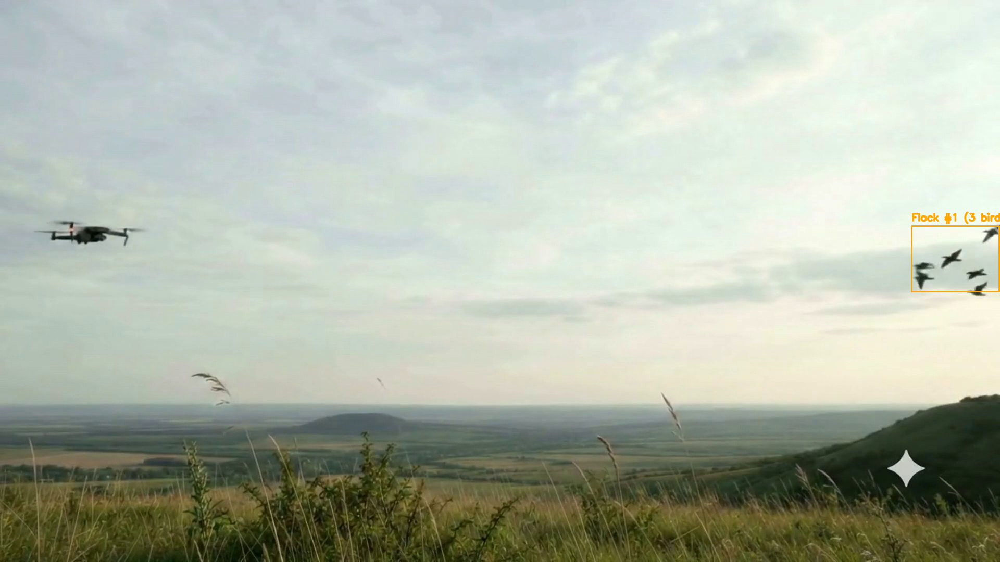

frame_000683.png


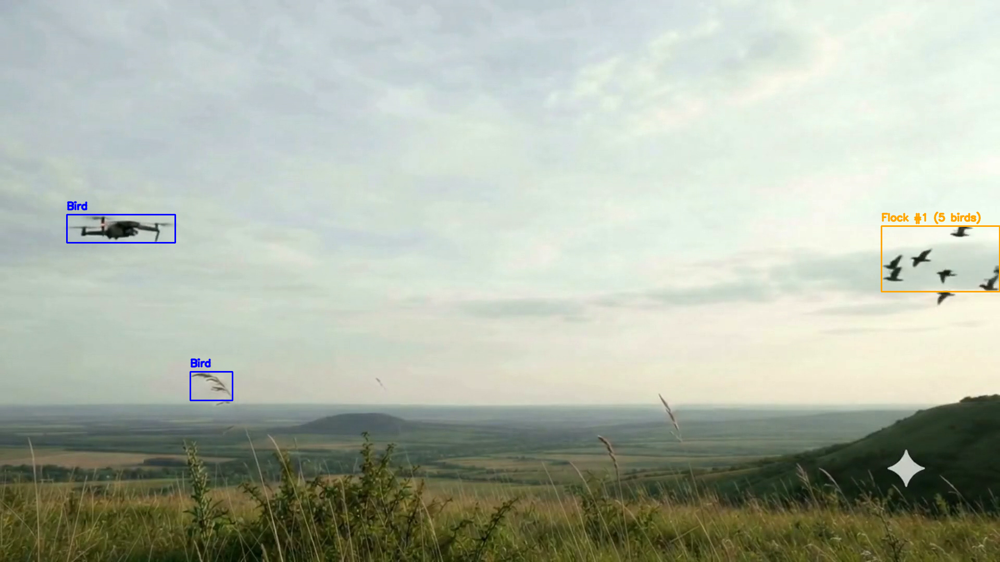

frame_000690.png


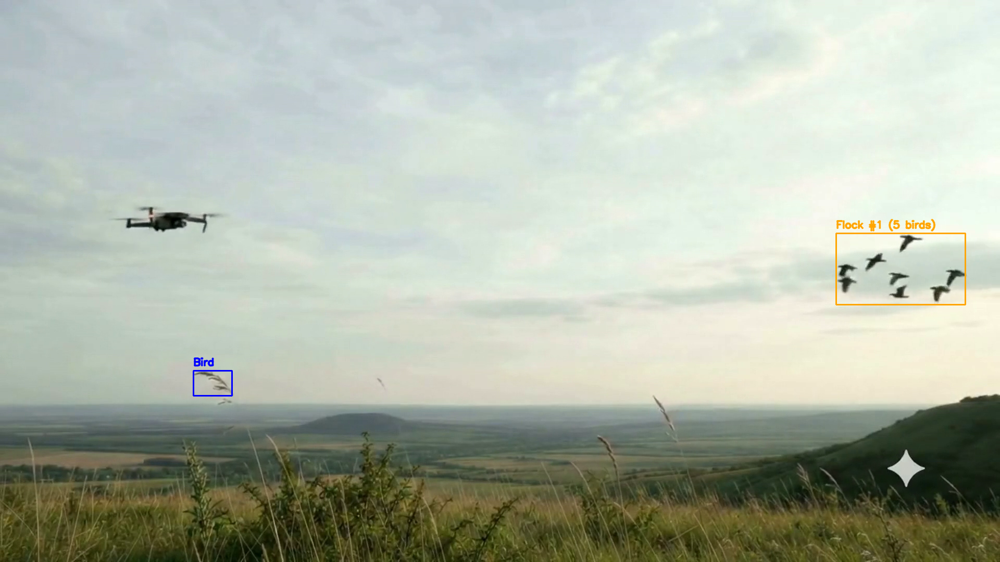

frame_000697.png


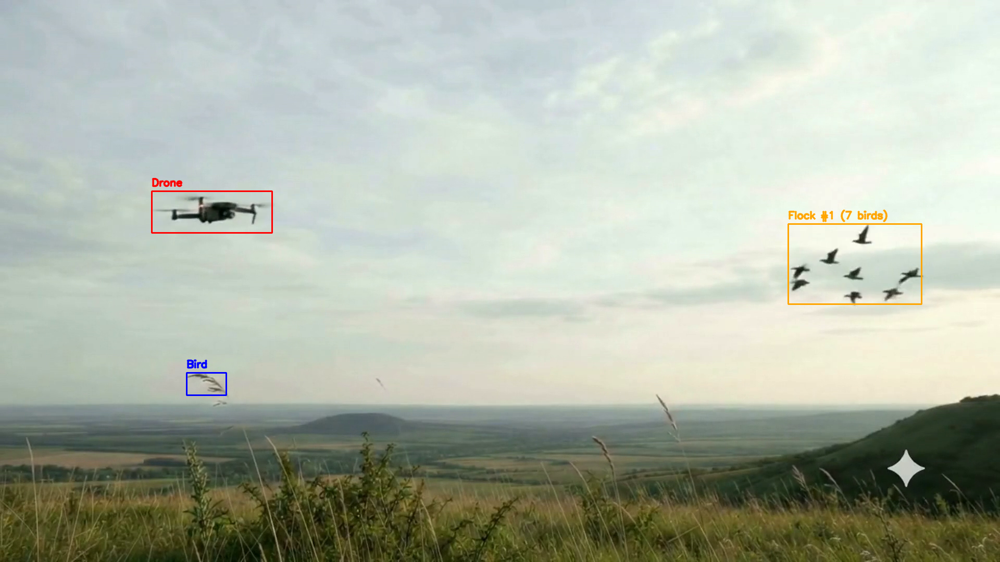

frame_000704.png


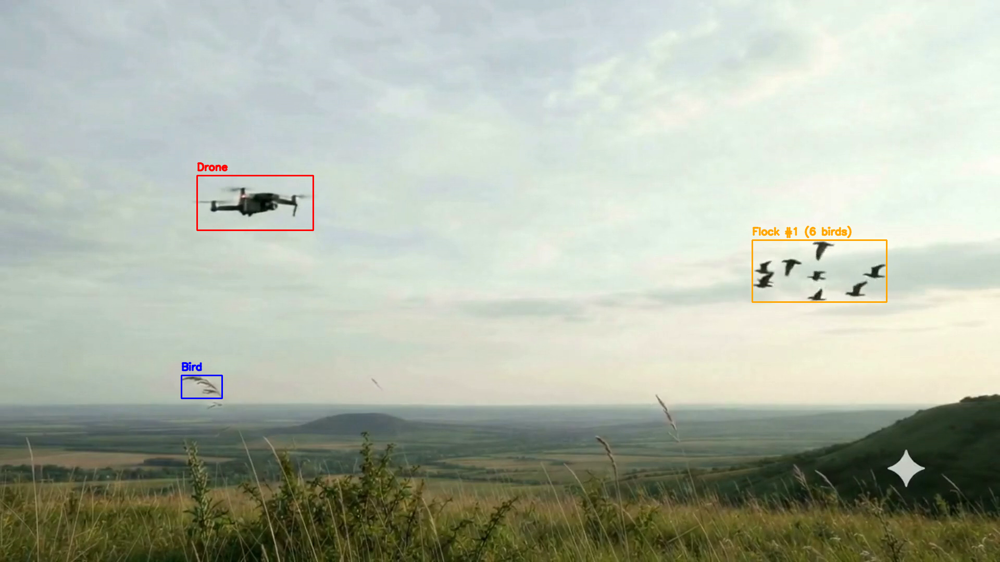

In [ ]:
from IPython.display import display, Image

for frame_index in selected_frames[:5]:
    filename = frame_files[frame_index]
    image_path = os.path.join(output_folder, filename)

    print(filename)
    display(Image(filename=image_path, width=900))

In [ ]:

import ast
import numpy as np
import pandas as pd
from sklearn.cluster import DBSCAN

def detect_bird_flocks(
    detections_df,
    flock_distance=100,
    min_birds=3
):
    flock_records = []

    # Only bird detections
    birds_df = detections_df[
        detections_df["class_label"] == "bird"
    ].copy()

    for frame_index, frame_birds in birds_df.groupby("frame_index"):

        if len(frame_birds) < min_birds:
            continue

        centers = frame_birds[
            ["center_x", "center_y"]
        ].to_numpy(dtype=float)

        # Group nearby birds
        clustering = DBSCAN(
            eps=flock_distance,
            min_samples=min_birds
        ).fit(centers)

        frame_birds = frame_birds.copy()
        frame_birds["flock_id"] = clustering.labels_

        # -1 means bird was not assigned to a flock
        for flock_id, group in frame_birds.groupby("flock_id"):

            if flock_id == -1:
                continue

            boxes = []

            for bbox in group["bounding_box"]:
                if isinstance(bbox, str):
                    bbox = ast.literal_eval(bbox)

                boxes.append(bbox)

            boxes = np.array(boxes, dtype=float)

            # Bounding box enclosing all birds in the flock
            x1 = float(boxes[:, 0].min())
            y1 = float(boxes[:, 1].min())
            x2 = float(boxes[:, 2].max())
            y2 = float(boxes[:, 3].max())

            flock_records.append({
                "frame_index": int(frame_index),
                "flock_id": int(flock_id),
                "class_label": "flock",
                "bird_count": len(group),
                "bounding_box": [x1, y1, x2, y2],
                "center_x": (x1 + x2) / 2,
                "center_y": (y1 + y2) / 2
            })

    return pd.DataFrame(
        flock_records,
        columns=[
            "frame_index",
            "flock_id",
            "class_label",
            "bird_count",
            "bounding_box",
            "center_x",
            "center_y"
        ]
    )


In [ ]:
import pandas as pd

df = pd.read_csv(
    "/content/drive/MyDrive/Drone/detections_video_drone_bird_1.csv"
)

flock_df = detect_bird_flocks(
    detections_df=df,
    flock_distance=100,
    min_birds=3
)

print("Flock detections:", len(flock_df))
print(flock_df.head())

flock_df.to_csv(
    "/content/drive/MyDrive/Drone/flock_detections_video_1.csv",
    index=False
)

Flock detections: 156
   frame_index  flock_id class_label  bird_count  \
0          676         0       flock           3   
1          677         0       flock           3   
2          678         0       flock           3   
3          680         0       flock           3   
4          681         0       flock           5   

                     bounding_box  center_x  center_y  
0  [1750.0, 434.0, 1918.0, 560.0]    1834.0     497.0  
1  [1751.0, 434.0, 1918.0, 560.0]    1834.5     497.0  
2  [1735.0, 439.0, 1917.0, 553.0]    1826.0     496.0  
3  [1705.0, 437.0, 1885.0, 536.0]    1795.0     486.5  
4  [1692.0, 434.0, 1919.0, 560.0]    1805.5     497.0  


In [ ]:

import os
import cv2

frames_root = "/content/drive/MyDrive/Drone/frames/video_drone_bird"
output_folder = "/content/drive/MyDrive/Drone/flock_detections"

os.makedirs(output_folder, exist_ok=True)

frame_files = sorted([
    f for f in os.listdir(frames_root)
    if f.lower().endswith((".png", ".jpg", ".jpeg"))
])

for i, frame_name in enumerate(frame_files):
    frame = cv2.imread(
        os.path.join(frames_root, frame_name)
    )

    if frame is None:
        continue

    frame_flocks = flock_df[
        flock_df["frame_index"] == i
    ]

    for _, flock in frame_flocks.iterrows():
        x1, y1, x2, y2 = map(
            int, flock["bounding_box"]
        )

        # Blue box around entire flock
        cv2.rectangle(
            frame,
            (x1, y1),
            (x2, y2),
            (255, 0, 0),
            3
        )

        label = f"Flock ({flock['bird_count']} birds)"

        cv2.putText(
            frame,
            label,
            (x1, max(25, y1 - 10)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.7,
            (255, 0, 0),
            2,
            cv2.LINE_AA
        )

    cv2.imwrite(
        os.path.join(output_folder, frame_name),
        frame
    )

print("Flock detection frames saved:", output_folder)


Flock detection frames saved: /content/drive/MyDrive/Drone/flock_detections


In [ ]:
print("Total flock detections:", len(flock_df))
print("Frames containing flocks:", flock_df["frame_index"].nunique())
print("Maximum birds in one flock:", flock_df["bird_count"].max())

Total flock detections: 156
Frames containing flocks: 153
Maximum birds in one flock: 9


In [ ]:
import os

frames_root = "/content/drive/MyDrive/Drone/frames/video_1"

frame_files = sorted([
    f for f in os.listdir(frames_root)
    if f.lower().endswith((".png", ".jpg", ".jpeg"))
])

flock_frame_indices = sorted(flock_df["frame_index"].unique())

print("Frames containing detected flocks:\n")

for frame_index in flock_frame_indices:
    print(frame_files[int(frame_index)])

Frames containing detected flocks:

frame_000677.png
frame_000678.png
frame_000679.png
frame_000681.png
frame_000682.png
frame_000683.png
frame_000684.png
frame_000685.png
frame_000686.png
frame_000687.png
frame_000688.png
frame_000689.png
frame_000690.png
frame_000691.png
frame_000692.png
frame_000693.png
frame_000694.png
frame_000695.png
frame_000696.png
frame_000697.png
frame_000698.png
frame_000699.png
frame_000700.png
frame_000701.png
frame_000702.png
frame_000703.png
frame_000704.png
frame_000706.png
frame_000707.png
frame_000708.png
frame_000709.png
frame_000710.png
frame_000711.png
frame_000712.png
frame_000713.png
frame_000716.png
frame_000717.png
frame_000718.png
frame_000719.png
frame_000720.png
frame_000721.png
frame_000722.png
frame_000723.png
frame_000724.png
frame_000725.png
frame_000729.png
frame_000731.png
frame_000732.png
frame_000733.png
frame_000734.png
frame_000735.png
frame_000737.png
frame_000738.png
frame_000739.png
frame_000740.png
frame_000741.png
frame_000742

Frame dimensions: 1920 x 1080


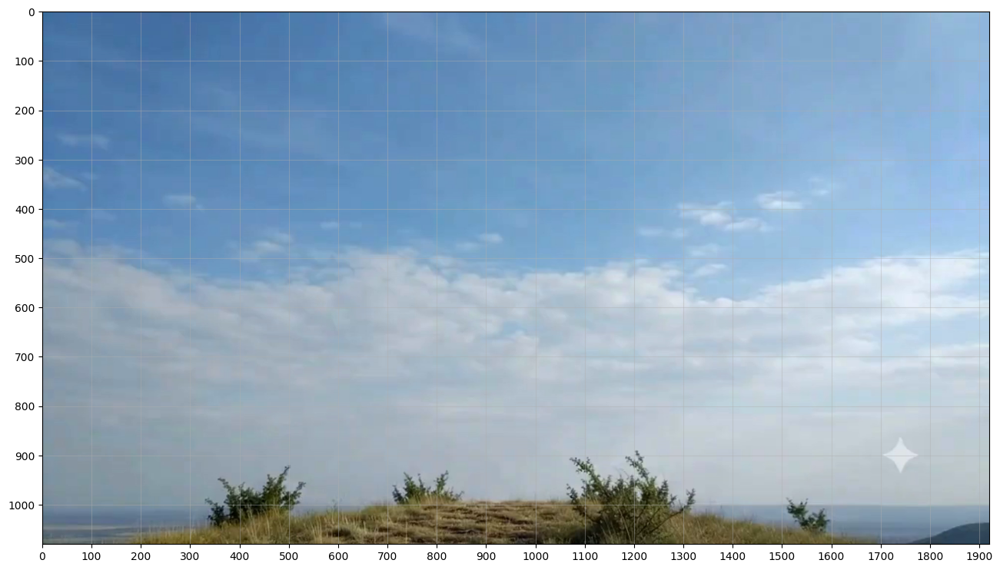

In [ ]:
import cv2
import matplotlib.pyplot as plt
import os

frames_root = "/content/drive/MyDrive/Drone/frames/video_drone_bird"

frame_files = sorted([
    f for f in os.listdir(frames_root)
    if f.lower().endswith((".png", ".jpg", ".jpeg"))
])

frame = cv2.imread(os.path.join(frames_root, frame_files[0]))
frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

height, width = frame.shape[:2]
print(f"Frame dimensions: {width} x {height}")

plt.figure(figsize=(16, 9))
plt.imshow(frame_rgb)
plt.xlim(0, width)
plt.ylim(height, 0)
plt.xticks(range(0, width + 1, 100))
plt.yticks(range(0, height + 1, 100))
plt.grid(alpha=0.4)
plt.show()

In [ ]:
df

,video_id,frame_directory,frame_index,file_name,file_path,class_label,bounding_box,confidence_score,center_x,center_y
0,1,drone_video_1,0,drone_video_1_frame_0000.jpg,/content/drive/MyDrive/Drone/detections/drone_...,drone,"[844, 165, 924, 246]",0.387733,884.0,205.5
1,1,drone_video_1,0,drone_video_1_frame_0000.jpg,/content/drive/MyDrive/Drone/detections/drone_...,drone,"[845, 169, 917, 244]",0.318391,881.0,206.5
2,1,drone_video_1,1,drone_video_1_frame_0001.jpg,/content/drive/MyDrive/Drone/detections/drone_...,drone,"[847, 172, 916, 248]",0.803412,881.5,210.0
3,1,drone_video_1,2,drone_video_1_frame_0002.jpg,/content/drive/MyDrive/Drone/detections/drone_...,drone,"[841, 175, 921, 253]",0.865342,881.0,214.0
4,1,drone_video_1,3,drone_video_1_frame_0003.jpg,/content/drive/MyDrive/Drone/detections/drone_...,drone,"[840, 176, 918, 257]",0.865357,879.0,216.5
...,...,...,...,...,...,...,...,...,...,...
604,2,drone_video_2,1481,drone_video_2_frame_1481.jpg,/content/drive/MyDrive/Drone/detections/drone_...,drone,"[1743, 29, 1784, 75]",0.162032,1763.5,52.0
605,2,drone_video_2,2069,drone_video_2_frame_2069.jpg,/content/drive/MyDrive/Drone/detections/drone_...,drone,"[1099, 232, 1130, 280]",0.466514,1114.5,256.0
606,2,drone_video_2,2070,drone_video_2_frame_2070.jpg,/content/drive/MyDrive/Drone/detections/drone_...,drone,"[1055, 202, 1086, 245]",0.177512,1070.5,223.5
607,2,drone_video_2,2071,drone_video_2_frame_2071.jpg,/content/drive/MyDrive/Drone/detections/drone_...,drone,"[1023, 176, 1055, 220]",0.191192,1039.0,198.0


In [ ]:
!pip install filterpy

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 178.0/178.0 kB 1.1 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for filterpy: filename=filterpy-1.4.5-py3-none-any.whl size=110543 sha256=7d953e0e39d537490cddf569caeea8634f988c70dec549d22e32a3744ffd480a
  Stored in directory: /root/.cache/pip/wheels/79/33/43/53b597b8f63de80842202a5fed633eea6f5ce3e3f6c6efbab8
Successfully built filterpy


In [ ]:
import cv2

input_video = "/content/drive/MyDrive/Drone/input_video/Drone_and_Bird_New_video.mp4"

cap = cv2.VideoCapture(input_video)
fps = cap.get(cv2.CAP_PROP_FPS)
cap.release()

print(f"Original video FPS: {fps}")

Original video FPS: 30.0


In [ ]:
from filterpy.kalman import KalmanFilter
import numpy as np

# def create_drone_tracker():
#     kf = KalmanFilter(dim_x=4, dim_z=2)
#     dt = 1.0

#     kf.F = np.array([[1, 0, dt, 0],
#                      [0, 1, 0, dt],
#                      [0, 0, 1, 0],
#                      [0, 0, 0, 1]])

#     kf.H = np.array([[1, 0, 0, 0],
#                      [0, 1, 0, 0]])

#     kf.P *= 1000.
#     kf.R = 5
#     kf.Q = 0.1

#     return kf

def create_drone_tracker(fps=29.839):
    dt = 1.0 / fps
    kf = KalmanFilter(dim_x=4, dim_z=2)

    kf.F = np.array([
        [1, 0, dt, 0],
        [0, 1, 0, dt],
        [0, 0, 1, 0],
        [0, 0, 0, 1]
    ], dtype=float)

    kf.H = np.array([
        [1, 0, 0, 0],
        [0, 1, 0, 0]
    ], dtype=float)

    kf.P = np.diag([100, 100, 1000, 1000])
    kf.R = np.eye(2) * 9.0

    # Constant-velocity model with random acceleration
    q = 25.0
    G = np.array([
        [0.5 * dt**2, 0],
        [0, 0.5 * dt**2],
        [dt, 0],
        [0, dt]
    ])
    kf.Q = q * G @ G.T

    return kf

def predict_future_positions(kf, horizons=(0.2, 0.5, 1.0)):
    x, y, vx, vy = kf.x.flatten()
    return {
        h: (float(x + vx*h), float(y + vy*h))
        for h in horizons
    }


In [ ]:
from filterpy.kalman import KalmanFilter
import numpy as np

def create_drone_tracker(fps=30.0):
    dt = 1.0 / fps
    kf = KalmanFilter(dim_x=4, dim_z=2)

    kf.F = np.array([
        [1, 0, dt, 0],
        [0, 1, 0, dt],
        [0, 0, 1, 0],
        [0, 0, 0, 1]
    ], dtype=float)

    kf.H = np.array([
        [1, 0, 0, 0],
        [0, 1, 0, 0]
    ], dtype=float)

    kf.P = np.diag([100, 100, 1000, 1000])
    kf.R = np.eye(2) * 9.0

    # Constant-velocity model with random acceleration
    q = 25.0
    G = np.array([
        [0.5 * dt**2, 0],
        [0, 0.5 * dt**2],
        [dt, 0],
        [0, dt]
    ])
    kf.Q = q * G @ G.T

    return kf

def predict_future_positions(kf, horizons=(0.2, 0.5, 1.0)):
    x, y, vx, vy = kf.x.flatten()
    return {
        h: (float(x + vx*h), float(y + vy*h))
        for h in horizons
    }


In [ ]:
#Original

import cv2
import os
import numpy as np

# def track_drone_filtered_frames(frame_folder, detections_df, output_video_name, fps=5):
#     images = sorted([img for img in os.listdir(frame_folder) if img.endswith(".jpg")])
#     if not images:
#         print(f"No images in {frame_folder}")
#         return

#     first_frame = cv2.imread(os.path.join(frame_folder, images[0]))
#     h, w, _ = first_frame.shape

#     out = cv2.VideoWriter(output_video_name, cv2.VideoWriter_fourcc(*'mp4v'), fps, (w, h))

#     tracker = create_drone_tracker()
#     initialized = False
#     trajectory = []

#     for i, img_name in enumerate(images):
#         frame = cv2.imread(os.path.join(frame_folder, img_name))

#         current_det = detections_df[detections_df['frame_index'] == i]

#         tracker.predict()

#         if not current_det.empty:
#             best_det = current_det.iloc[0]
#             z = np.array([[best_det['center_x']], [best_det['center_y']]])

#             if not initialized:
#                 tracker.x[:2] = z
#                 initialized = True
#             else:
#                 tracker.update(z)

#             bbox = best_det['bounding_box']
#             cv2.rectangle(frame, (bbox[0], bbox[1]), (bbox[2], bbox[3]), (0, 0, 255), 2)

#             curr_x, curr_y = int(tracker.x[0]), int(tracker.x[1])
#             trajectory.append((curr_x, curr_y))

#             if len(trajectory) > 1:
#                 for j in range(1, len(trajectory)):
#                     cv2.line(frame, trajectory[j-1], trajectory[j], (0, 255, 0), 2)

#             out.write(frame)

#     out.release()
#     print(f"Filtered video saved to: {output_video_name}")

import os
import cv2
import numpy as np
import pandas as pd
from collections import deque

def track_drone_motion(
    frame_folder, detections_df, output_video_name,
    fps=29.839, trail_length=50
):
    images = sorted(
        f for f in os.listdir(frame_folder)
        if f.lower().endswith(".png")
    )
    if not images:
        return pd.DataFrame()

    first = cv2.imread(os.path.join(frame_folder, images[0]))
    h, w = first.shape[:2]

    out = cv2.VideoWriter(
        output_video_name,
        cv2.VideoWriter_fourcc(*"mp4v"),
        fps, (w, h)
    )
    if not out.isOpened():
        raise RuntimeError("Could not open video writer")

    tracker = create_drone_tracker(fps)
    initialized = False
    trajectory = deque(maxlen=trail_length)
    records = []

    # Choose highest-confidence detection per frame
    best_detections = (
        detections_df.sort_values(
            "confidence_score", ascending=False
        ).drop_duplicates("frame_index")
        .set_index("frame_index")
    )

    def point(x, y):
        return (int(round(x)), int(round(y)))

    for i, name in enumerate(images):
        frame = cv2.imread(os.path.join(frame_folder, name))
        if frame is None:
            raise RuntimeError(f"Could not read {name}")

        detected = i in best_detections.index
        observed_x = observed_y = np.nan
        prior_x = prior_y = np.nan

        if initialized:
            tracker.predict()
            prior_x = float(tracker.x[0, 0])
            prior_y = float(tracker.x[1, 0])

        if detected:
            det = best_detections.loc[i]
            observed_x = float(det["center_x"])
            observed_y = float(det["center_y"])

            z = np.array([observed_x, observed_y])

            if not initialized:
                tracker.x = np.array([
                    [observed_x], [observed_y],
                    [0.0], [0.0]
                ])
                initialized = True
            else:
                tracker.update(z)

            bbox = det["bounding_box"]
            cv2.rectangle(
                frame, point(bbox[0], bbox[1]),
                point(bbox[2], bbox[3]),
                (0, 0, 255), 2
            )

            cv2.circle(
                frame, point(observed_x, observed_y),
                4, (0, 0, 255), -1
            )

        if initialized:
            x, y, vx, vy = tracker.x.flatten()
            x, y, vx, vy = map(float, (x, y, vx, vy))
            speed = float(np.hypot(vx, vy))
            direction = float(
                np.degrees(np.arctan2(vy, vx))
            )

            trajectory.append(point(x, y))

            # Historical trajectory in green
            for j in range(1, len(trajectory)):
                cv2.line(
                    frame, trajectory[j-1],
                    trajectory[j], (0, 255, 0), 2
                )

            cv2.circle(
                frame, point(x, y), 5, (255, 0, 0), -1
            )

            # Future positions: 0.2, 0.5, 1.0 seconds
            predictions = predict_future_positions(tracker)
            colors = {
                0.2: (0, 255, 255),
                0.5: (0, 165, 255),
                1.0: (255, 0, 255)
            }

            for horizon, (px, py) in predictions.items():
                cv2.line(
                    frame, point(x, y), point(px, py),
                    colors[horizon], 1
                )
                cv2.circle(
                    frame, point(px, py),
                    5, colors[horizon], -1
                )
                cv2.putText(
                    frame, f"+{horizon}s",
                    point(px + 7, py - 7),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.45, colors[horizon], 1
                )

            cv2.putText(
                frame,
                f"Speed: {speed:.1f} px/s",
                (15, 30),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.65, (255, 255, 255), 2
            )

            record = {
                "frame_index": i,
                "time_seconds": i / fps,
                "detected": detected,
                "observed_x": observed_x,
                "observed_y": observed_y,
                "prior_x": prior_x,
                "prior_y": prior_y,
                "filtered_x": x,
                "filtered_y": y,
                "velocity_x": vx,
                "velocity_y": vy,
                "speed_px_s": speed,
                "direction_degrees": direction
            }

            for horizon, (px, py) in predictions.items():
                suffix = str(horizon).replace(".", "_")
                record[f"pred_x_{suffix}s"] = px
                record[f"pred_y_{suffix}s"] = py

            records.append(record)

        # Write every frame, including missing detections
        out.write(frame)

    out.release()
    print(f"Saved: {output_video_name}")
    return pd.DataFrame(records)


In [ ]:
# Only drone
def track_drone_motion(
    frame_folder,
    detections_df,
    output_video_name,
    fps=29.839,
    trail_seconds=5,
    prediction_seconds=1.0
):
    import os
    import ast
    import cv2
    import numpy as np
    import pandas as pd
    from collections import deque

    images = sorted([
        f for f in os.listdir(frame_folder)
        if f.lower().endswith((".png", ".jpg", ".jpeg"))
    ])

    if not images:
        raise ValueError("No image frames found.")

    first_frame = cv2.imread(
        os.path.join(frame_folder, images[0])
    )

    if first_frame is None:
        raise RuntimeError("Cannot read first frame.")

    height, width = first_frame.shape[:2]

    writer = cv2.VideoWriter(
        output_video_name,
        cv2.VideoWriter_fourcc(*"mp4v"),
        fps,
        (width, height)
    )

    if not writer.isOpened():
        raise RuntimeError("Could not open output video writer.")

    # Kalman filter remains active internally
    tracker = create_drone_tracker(fps=fps)
    initialized = False

    # Store actual YOLO positions with their frame indices
    trail_frames = max(1, round(trail_seconds * fps))
    history = deque()

    tracking_records = []

    # One detection per frame (highest confidence)
    best_detections = (
        detections_df
        .sort_values(
            "confidence_score",
            ascending=False
        )
        .drop_duplicates("frame_index")
        .set_index("frame_index")
    )

    def point(x, y):
        return (int(round(x)), int(round(y)))

    try:
        for i, image_name in enumerate(images):
            frame = cv2.imread(
                os.path.join(frame_folder, image_name)
            )

            if frame is None:
                raise RuntimeError(
                    f"Cannot read frame: {image_name}"
                )

            detected = i in best_detections.index

            observed_x = np.nan
            observed_y = np.nan

            # Predict Kalman state internally
            if initialized:
                tracker.predict()

            if detected:
                detection = best_detections.loc[i]

                observed_x = float(detection["center_x"])
                observed_y = float(detection["center_y"])

                measurement = np.array([
                    observed_x,
                    observed_y
                ])

                if not initialized:
                    tracker.x = np.array([
                        [observed_x],
                        [observed_y],
                        [0.0],
                        [0.0]
                    ])
                    initialized = True
                else:
                    tracker.update(measurement)

                # Draw red YOLO bounding box
                bbox = detection["bounding_box"]

                if isinstance(bbox, str):
                    bbox = ast.literal_eval(bbox)

                x1, y1, x2, y2 = map(int, bbox)

                cv2.rectangle(
                    frame,
                    (x1, y1),
                    (x2, y2),
                    (0, 0, 255),
                    2
                )

                # Add actual observed position to history
                history.append((
                    i,
                    point(observed_x, observed_y)
                ))

            # Remove historical points older than 5 seconds
            while history and i - history[0][0] > trail_frames:
                history.popleft()

            # Draw actual historical trajectory
            history_list = list(history)

            for j in range(1, len(history_list)):
                previous_frame, previous_point = history_list[j - 1]
                current_frame, current_point = history_list[j]

                # Don't connect across long detection gaps
                if current_frame - previous_frame > 3:
                    continue

                cv2.line(
                    frame,
                    previous_point,
                    current_point,
                    (0, 255, 0),
                    2,
                    cv2.LINE_AA
                )

            if initialized:
                x, y, vx, vy = map(
                    float,
                    tracker.x.flatten()
                )

                speed = float(np.hypot(vx, vy))
                if detected:
                  speed_label = f"{speed:.1f} px/s"

                  text_x = max(0, min(x2 + 10, width - 150))
                  text_y = max(y1 + 20, 25)

                  cv2.putText(
                      frame,
                      speed_label,
                      (text_x, text_y),
                      cv2.FONT_HERSHEY_SIMPLEX,
                      0.6,
                      (255, 255, 255),
                      2,
                      cv2.LINE_AA
                  )

                # Start arrow at actual detected position
                # Only show arrow when drone is detected
                if detected:
                    start_x = observed_x
                    start_y = observed_y

                    # Predict displacement using Kalman velocity
                    end_x = start_x + vx * prediction_seconds
                    end_y = start_y + vy * prediction_seconds

                    # cv2.arrowedLine(
                    #     frame,
                    #     point(start_x, start_y),
                    #     point(end_x, end_y),
                    #     (0, 255, 255),
                    #     3,
                    #     cv2.LINE_AA,
                    #     tipLength=0.15
                    # )
                    # Draw a dotted yellow prediction line
                    start_point = np.array([start_x, start_y], dtype=float)
                    end_point = np.array([end_x, end_y], dtype=float)

                    distance = np.linalg.norm(end_point - start_point)

                    dot_spacing = 12  # Distance between dots in pixels
                    dot_radius = 3

                    if distance > 0:
                        direction = (end_point - start_point) / distance

                        for d in np.arange(0, distance + 1, dot_spacing):
                            dot_position = start_point + direction * min(d, distance)

                            cv2.circle(
                                frame,
                                point(dot_position[0], dot_position[1]),
                                dot_radius,
                                (0, 255, 255),
                                -1,
                                cv2.LINE_AA
                            )

                    if distance > 0:
                      arrow_length = min(25, distance * 0.3)

                      arrow_start = end_point - direction * arrow_length

                      cv2.arrowedLine(
                          frame,
                          point(arrow_start[0], arrow_start[1]),
                          point(end_x, end_y),
                          (0, 255, 255),
                          3,
                          cv2.LINE_AA,
                          tipLength=0.6
                      )

                    cv2.putText(
                        frame,
                        f"+{prediction_seconds:.1f}s prediction",
                        point(end_x + 10, end_y - 10),
                        cv2.FONT_HERSHEY_SIMPLEX,
                        0.5,
                        (255, 255, 255),
                        2,
                        cv2.LINE_AA
                    )

                tracking_records.append({
                    "frame_index": i,
                    "time_seconds": i / fps,
                    "detected": detected,
                    "observed_x": observed_x,
                    "observed_y": observed_y,
                    "filtered_x": x,
                    "filtered_y": y,
                    "velocity_x": vx,
                    "velocity_y": vy,
                    "speed_px_s": speed,
                    "predicted_x_1s": (
                        observed_x + vx * prediction_seconds
                        if detected else np.nan
                    ),
                    "predicted_y_1s": (
                        observed_y + vy * prediction_seconds
                        if detected else np.nan
                    )
                })

            writer.write(frame)

            if (i + 1) % 100 == 0:
                print(
                    f"Processed {i+1}/{len(images)} frames",
                    flush=True
                )

    finally:
        writer.release()

    print("Video saved:", output_video_name)

    return pd.DataFrame(tracking_records)


In [ ]:
#For drones and birds old version without flocks and without multi objects
def track_drone_motion(
    frame_folder,
    detections_df,
    output_video_name,
    fps=30.0,
    trail_seconds=5,
    prediction_seconds=1.0
):
    import os
    import ast
    import cv2
    import numpy as np
    import pandas as pd
    from collections import deque

    images = sorted([
        f for f in os.listdir(frame_folder)
        if f.lower().endswith((".png", ".jpg", ".jpeg"))
    ])

    if not images:
        raise ValueError("No image frames found.")

    first_frame = cv2.imread(
        os.path.join(frame_folder, images[0])
    )

    if first_frame is None:
        raise RuntimeError("Cannot read first frame.")

    height, width = first_frame.shape[:2]

    writer = cv2.VideoWriter(
        output_video_name,
        cv2.VideoWriter_fourcc(*"mp4v"),
        fps,
        (width, height)
    )

    if not writer.isOpened():
        raise RuntimeError("Could not open output video writer.")

    # Kalman filter remains active internally
    tracker = create_drone_tracker(fps=fps)
    initialized = False

    # Store actual YOLO positions with their frame indices
    trail_frames = max(1, round(trail_seconds * fps))
    history = deque()

    tracking_records = []

    # One detection per frame (highest confidence)
    best_detections = (
        detections_df
        .sort_values(
            "confidence_score",
            ascending=False
        )
        .drop_duplicates("frame_index")
        .set_index("frame_index")
    )

    def point(x, y):
        return (int(round(x)), int(round(y)))

    try:
        for i, image_name in enumerate(images):
            frame = cv2.imread(
                os.path.join(frame_folder, image_name)
            )

            if frame is None:
                raise RuntimeError(
                    f"Cannot read frame: {image_name}"
                )

            detected = i in best_detections.index

            observed_x = np.nan
            observed_y = np.nan

            # Predict Kalman state internally
            if initialized:
                tracker.predict()

            if detected:
                detection = best_detections.loc[i]

                observed_x = float(detection["center_x"])
                observed_y = float(detection["center_y"])

                measurement = np.array([
                    observed_x,
                    observed_y
                ])

                if not initialized:
                    tracker.x = np.array([
                        [observed_x],
                        [observed_y],
                        [0.0],
                        [0.0]
                    ])
                    initialized = True
                else:
                    tracker.update(measurement)

                # Draw red YOLO bounding box
                bbox = detection["bounding_box"]

                if isinstance(bbox, str):
                    bbox = ast.literal_eval(bbox)

                x1, y1, x2, y2 = map(int, bbox)

                cv2.rectangle(
                    frame,
                    (x1, y1),
                    (x2, y2),
                    (0, 0, 255),
                    2
                )

                # Add actual observed position to history
                history.append((
                    i,
                    point(observed_x, observed_y)
                ))

            # Remove historical points older than 5 seconds
            while history and i - history[0][0] > trail_frames:
                history.popleft()

            # Draw actual historical trajectory
            history_list = list(history)

            for j in range(1, len(history_list)):
                previous_frame, previous_point = history_list[j - 1]
                current_frame, current_point = history_list[j]

                # Don't connect across long detection gaps
                if current_frame - previous_frame > 3:
                    continue

                cv2.line(
                    frame,
                    previous_point,
                    current_point,
                    (0, 255, 0),
                    2,
                    cv2.LINE_AA
                )

            if initialized:
                x, y, vx, vy = map(
                    float,
                    tracker.x.flatten()
                )

                speed = float(np.hypot(vx, vy))
                if detected:
                  speed_label = f"{speed:.1f} px/s"

                  text_x = max(0, min(x2 + 10, width - 150))
                  text_y = max(y1 + 20, 25)

                  cv2.putText(
                      frame,
                      speed_label,
                      (text_x, text_y),
                      cv2.FONT_HERSHEY_SIMPLEX,
                      0.6,
                      (255, 255, 255),
                      2,
                      cv2.LINE_AA
                  )

                # Start arrow at actual detected position
                # Only show arrow when drone is detected
                if detected:
                    start_x = observed_x
                    start_y = observed_y

                    # Predict displacement using Kalman velocity
                    end_x = start_x + vx * prediction_seconds
                    end_y = start_y + vy * prediction_seconds

                    # cv2.arrowedLine(
                    #     frame,
                    #     point(start_x, start_y),
                    #     point(end_x, end_y),
                    #     (0, 255, 255),
                    #     3,
                    #     cv2.LINE_AA,
                    #     tipLength=0.15
                    # )
                    # Draw a dotted yellow prediction line
                    start_point = np.array([start_x, start_y], dtype=float)
                    end_point = np.array([end_x, end_y], dtype=float)

                    distance = np.linalg.norm(end_point - start_point)

                    dot_spacing = 12  # Distance between dots in pixels
                    dot_radius = 3

                    if distance > 0:
                        direction = (end_point - start_point) / distance

                        for d in np.arange(0, distance + 1, dot_spacing):
                            dot_position = start_point + direction * min(d, distance)

                            cv2.circle(
                                frame,
                                point(dot_position[0], dot_position[1]),
                                dot_radius,
                                (0, 255, 255),
                                -1,
                                cv2.LINE_AA
                            )

                    if distance > 0:
                      arrow_length = min(25, distance * 0.3)

                      arrow_start = end_point - direction * arrow_length

                      cv2.arrowedLine(
                          frame,
                          point(arrow_start[0], arrow_start[1]),
                          point(end_x, end_y),
                          (0, 255, 255),
                          3,
                          cv2.LINE_AA,
                          tipLength=0.6
                      )

                    cv2.putText(
                        frame,
                        f"+{prediction_seconds:.1f}s prediction",
                        point(end_x + 10, end_y - 10),
                        cv2.FONT_HERSHEY_SIMPLEX,
                        0.5,
                        (255, 255, 255),
                        2,
                        cv2.LINE_AA
                    )

                tracking_records.append({
                    "frame_index": i,
                    "time_seconds": i / fps,
                    "detected": detected,
                    "observed_x": observed_x,
                    "observed_y": observed_y,
                    "filtered_x": x,
                    "filtered_y": y,
                    "velocity_x": vx,
                    "velocity_y": vy,
                    "speed_px_s": speed,
                    "predicted_x_1s": (
                        observed_x + vx * prediction_seconds
                        if detected else np.nan
                    ),
                    "predicted_y_1s": (
                        observed_y + vy * prediction_seconds
                        if detected else np.nan
                    )
                })

            writer.write(frame)

            if (i + 1) % 100 == 0:
                print(
                    f"Processed {i+1}/{len(images)} frames",
                    flush=True
                )

    finally:
        writer.release()

    print("Video saved:", output_video_name)

    return pd.DataFrame(tracking_records)


In [ ]:

import os
import ast
import cv2
import numpy as np
import pandas as pd

from collections import deque, Counter
from scipy.optimize import linear_sum_assignment


def track_multiple_objects(
    frame_folder,
    detections_df,
    output_video_name,
    fps=30.0,
    trail_seconds=5.0,
    prediction_seconds=1.0,
    match_distance=100,
    max_missing=30,
    flock_membership_distance=120
):
    # --------------------------------------------------
    # 1. Load frames and initialize video writer
    # --------------------------------------------------

    frame_files = sorted([
        f for f in os.listdir(frame_folder)
        if f.lower().endswith((".png", ".jpg", ".jpeg"))
    ])

    if not frame_files:
        raise ValueError("No video frames found.")

    first_frame = cv2.imread(
        os.path.join(frame_folder, frame_files[0])
    )

    if first_frame is None:
        raise ValueError("Could not read the first frame.")

    height, width = first_frame.shape[:2]

    os.makedirs(
        os.path.dirname(os.path.abspath(output_video_name)),
        exist_ok=True
    )

    writer = cv2.VideoWriter(
        output_video_name,
        cv2.VideoWriter_fourcc(*"mp4v"),
        fps,
        (width, height)
    )

    if not writer.isOpened():
        raise RuntimeError("Could not open video writer.")

    # --------------------------------------------------
    # 2. Prepare detections
    # --------------------------------------------------

    detections_df = detections_df.copy()

    def parse_bbox(value):
        if isinstance(value, str):
            value = ast.literal_eval(value)

        return np.asarray(value, dtype=float)

    detections_df["bounding_box"] = (
        detections_df["bounding_box"].apply(parse_bbox)
    )

    detections_by_frame = {
        int(frame_index): group.to_dict("records")
        for frame_index, group in
        detections_df.groupby("frame_index")
    }

    def bbox_center(box):
        return np.array([
            (box[0] + box[2]) / 2,
            (box[1] + box[3]) / 2
        ], dtype=float)

    def pixel_point(position):
        return tuple(
            int(round(float(value))) for value in position
        )

    # --------------------------------------------------
    # 3. Track storage
    # --------------------------------------------------

    tracks = {}
    next_track_id = 1
    tracking_records = []

    trail_frames = max(1, round(trail_seconds * fps))

    colors = {
        "drone": (0, 0, 255),   # Red
        "bird": (255, 0, 0),    # Blue
        "flock": (0, 165, 255)  # Orange
    }

    def create_track(detection, frame_index, track_id):
        measurement = bbox_center(
            detection["bounding_box"]
        )

        kf = create_drone_tracker(fps=fps)

        kf.x = np.array([
            [measurement[0]],
            [measurement[1]],
            [0.0],
            [0.0]
        ])

        kind = detection["class_label"]

        return {
            "kf": kf,
            "class_label": kind,
            "class_history": deque([kind], maxlen=15),
            "bounding_box": detection["bounding_box"],
            "bird_count": int(
                detection.get("bird_count", 0)
                if pd.notna(detection.get("bird_count", 0))
                else 0
            ),
            "history": deque([
                (frame_index, kf.x[:2, 0].copy())
            ]),
            "missing": 0,
            "age": 1
        }

    # --------------------------------------------------
    # 4. Draw dotted prediction with arrowhead
    # --------------------------------------------------

    def draw_prediction(frame, start, velocity):
        end = start + velocity * prediction_seconds

        displacement = end - start
        distance = np.linalg.norm(displacement)

        if distance < 1:
            return end

        direction = displacement / distance

        for d in np.arange(0, distance + 1, 12):
            position = start + direction * min(d, distance)

            cv2.circle(
                frame,
                pixel_point(position),
                3,
                (0, 255, 255),
                -1,
                cv2.LINE_AA
            )

        arrow_length = min(25, distance * 0.3)
        arrow_start = end - direction * arrow_length

        cv2.arrowedLine(
            frame,
            pixel_point(arrow_start),
            pixel_point(end),
            (0, 255, 255),
            3,
            cv2.LINE_AA,
            tipLength=0.6
        )

        return end

    # --------------------------------------------------
    # 5. Process each frame
    # --------------------------------------------------

    try:
        for frame_index, file_name in enumerate(frame_files):

            frame_path = os.path.join(
                frame_folder, file_name
            )

            frame = cv2.imread(frame_path)

            if frame is None:
                raise RuntimeError(
                    f"Could not read frame: {file_name}"
                )

            detections = detections_by_frame.get(
                frame_index, []
            )

            # A. Predict positions of existing tracks
            for track in tracks.values():
                track["kf"].predict()
                track["missing"] += 1
                track["age"] += 1

            # Suppress individual bird detections that likely
            # belong to an already-established flock.

            existing_flocks = [
                track
                for track in tracks.values()
                if track["class_label"] == "flock"
                and track["missing"] <= max_missing
            ]

            filtered_detections = []

            for detection in detections:

                if detection["class_label"] != "bird":
                    filtered_detections.append(detection)
                    continue

                bird_center = bbox_center(
                    detection["bounding_box"]
                )

                belongs_to_flock = False

                for flock in existing_flocks:

                    flock_box = flock["bounding_box"]
                    fx1, fy1, fx2, fy2 = flock_box

                    # Distance from bird center to the nearest
                    # point on the last observed flock box.
                    nearest_x = np.clip(
                        bird_center[0], fx1, fx2
                    )
                    nearest_y = np.clip(
                        bird_center[1], fy1, fy2
                    )

                    distance = np.linalg.norm(
                        bird_center -
                        np.array([nearest_x, nearest_y])
                    )

                    if distance <= flock_membership_distance:
                        belongs_to_flock = True
                        break

                if not belongs_to_flock:
                    filtered_detections.append(detection)

            detections = filtered_detections

            # B. Build detection-to-track cost matrix
            track_ids = list(tracks.keys())

            matched_track_ids = set()
            matched_detection_ids = set()

            if track_ids and detections:

                cost_matrix = np.full(
                    (len(track_ids), len(detections)),
                    1e6,
                    dtype=float
                )

                for row, track_id in enumerate(track_ids):
                    track = tracks[track_id]

                    predicted_center = (
                        track["kf"].x[:2, 0]
                    )

                    for col, detection in enumerate(detections):

                        detection_kind = (
                            detection["class_label"]
                        )

                        track_kind = track["class_label"]

                        # Flocks only match other flocks.
                        # Birds and drones can match each other
                        # to tolerate temporary YOLO class errors.
                        if (
                            (track_kind == "flock") !=
                            (detection_kind == "flock")
                        ):
                            continue

                        observed_center = bbox_center(
                            detection["bounding_box"]
                        )

                        distance = np.linalg.norm(
                            predicted_center - observed_center
                        )

                        if distance <= match_distance:
                            cost_matrix[row, col] = distance

                rows, cols = linear_sum_assignment(
                    cost_matrix
                )

                # C. Update matched tracks
                for row, col in zip(rows, cols):

                    if cost_matrix[row, col] >= 1e6:
                        continue

                    track_id = track_ids[row]
                    detection = detections[col]
                    track = tracks[track_id]

                    measurement = bbox_center(
                        detection["bounding_box"]
                    )

                    track["kf"].update(measurement)

                    track["bounding_box"] = (
                        detection["bounding_box"]
                    )

                    track["missing"] = 0

                    # Store Kalman-filtered position instead of raw YOLO center
                    filtered_position = track["kf"].x[:2, 0].copy()

                    track["history"].append(
                        (frame_index, filtered_position)
                    )

                    new_class = detection["class_label"]

                    track["class_history"].append(new_class)

                    # Smooth bird/drone classification
                    # using recent matched predictions.
                    counts = Counter(track["class_history"])
                    track["class_label"] = (
                        counts.most_common(1)[0][0]
                    )

                    count = detection.get("bird_count", 0)
                    track["bird_count"] = (
                        int(count) if pd.notna(count) else 0
                    )

                    matched_track_ids.add(track_id)
                    matched_detection_ids.add(col)

            # D. Create tracks for unmatched detections
            for detection_index, detection in enumerate(
                detections
            ):

                if detection_index in matched_detection_ids:
                    continue

                tracks[next_track_id] = create_track(
                    detection,
                    frame_index,
                    next_track_id
                )

                next_track_id += 1

            # E. Remove tracks missing too long
            for track_id in list(tracks.keys()):
                if tracks[track_id]["missing"] > max_missing:
                    del tracks[track_id]

            # --------------------------------------------------
            # 6. Draw each tracked object
            # --------------------------------------------------

            for track_id, track in tracks.items():

                # Don't draw boxes for missing detections
                if track["missing"] != 0:
                    continue

                kf = track["kf"]

                x, y, vx, vy = map(
                    float, kf.x.flatten()
                )

                velocity = np.array([vx, vy])
                speed = float(np.linalg.norm(velocity))

                box = track["bounding_box"]
                x1, y1, x2, y2 = map(int, box)

                kind = track["class_label"]
                color = colors.get(kind, (255, 255, 255))

                # Bounding box
                cv2.rectangle(
                    frame,
                    (x1, y1),
                    (x2, y2),
                    color,
                    2
                )

                label = f"{kind.title()} #{track_id}"

                if kind == "flock":
                    label += (
                        f" ({track['bird_count']} birds)"
                    )

                cv2.putText(
                    frame,
                    label,
                    (x1, max(25, y1 - 10)),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.65,
                    color,
                    2,
                    cv2.LINE_AA
                )

                # Velocity label
                cv2.putText(
                    frame,
                    f"{speed:.1f} px/s",
                    (
                        max(0, min(x2 + 8, width - 160)),
                        max(25, y1 + 20)
                    ),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.6,
                    (255, 255, 255),
                    2,
                    cv2.LINE_AA
                )

                # Green historical trajectory
                history = track["history"]

                while (
                    history and
                    frame_index - history[0][0] > trail_frames
                ):
                    history.popleft()

                history_points = list(history)

                for j in range(1, len(history_points)):

                    prev_frame, prev_point = history_points[j - 1]
                    curr_frame, curr_point = history_points[j]

                    # Avoid connecting long detection gaps
                    if curr_frame - prev_frame > 3:
                        continue

                    cv2.line(
                        frame,
                        pixel_point(prev_point),
                        pixel_point(curr_point),
                        (0, 255, 0),
                        2,
                        cv2.LINE_AA
                    )

                # Yellow predicted future trajectory
                observed_center = bbox_center(box)

                filtered_center = np.array([x, y])

                predicted_position = draw_prediction(
                    frame,
                    filtered_center,
                    velocity
                )

                # --------------------------------------------------
                # 7. Save tracking measurements
                # --------------------------------------------------

                tracking_records.append({
                    "frame_index": frame_index,
                    "time_seconds": frame_index / fps,
                    "track_id": track_id,
                    "class_label": kind,
                    "bird_count": track["bird_count"],
                    "observed_x": float(observed_center[0]),
                    "observed_y": float(observed_center[1]),
                    "filtered_x": x,
                    "filtered_y": y,
                    "velocity_x": vx,
                    "velocity_y": vy,
                    "speed_px_s": speed,
                    "predicted_x_1s": float(
                        predicted_position[0]
                    ),
                    "predicted_y_1s": float(
                        predicted_position[1]
                    )
                })

            writer.write(frame)

            if (frame_index + 1) % 100 == 0:
                print(
                    f"Processed {frame_index + 1}/"
                    f"{len(frame_files)} frames"
                )

    finally:
        writer.release()

    print("Tracking video saved:", output_video_name)

    return pd.DataFrame(tracking_records)


In [ ]:
# import os

# frames_root = "/content/drive/MyDrive/Drone/frames"
# output_root = "/content/drive/MyDrive/Drone"

# frame_dirs = sorted([
#     d for d in os.listdir(frames_root)
#     if os.path.isdir(os.path.join(frames_root, d))
# ])

# for video_id, frame_dir_name in enumerate(frame_dirs, start=1):
#     frame_folder = os.path.join(frames_root, frame_dir_name)

#     detections_for_video = df[df["video_id"] == video_id]

#     if detections_for_video.empty:
#         print(f"Skipping video_id={video_id}, folder={frame_dir_name} (no detections)")
#         continue

#     output_video_name = os.path.join(
#         output_root,
#         f"tracking_video_{video_id}.mp4"
#     )

#     print(f"Tracking video_id={video_id}, folder={frame_dir_name}")

#     track_drone_filtered_frames(
#         frame_folder=frame_folder,
#         detections_df=detections_for_video,
#         output_video_name=output_video_name
#     )

import os
import pandas as pd

frames_root = "/content/drive/MyDrive/Drone/frames/video_1"
output_root = "/content/drive/MyDrive/Drone/motion_analysis"
os.makedirs(output_root, exist_ok=True)

video_id = 1
folder_name = "video_1"

# Process only video_1
video_detections = df[df["video_id"] == video_id]

output_video = os.path.join(
    output_root, f"motion_video_{video_id}.mp4"
)

print(f"Processing {folder_name}...", flush=True)

tracking_df = track_drone_motion(
    frame_folder=frames_root,
    detections_df=video_detections,
    output_video_name=output_video,
    fps=29.839
)

if not tracking_df.empty:
    tracking_df["video_id"] = video_id
    tracking_df["video_name"] = folder_name

    tracking_df.to_csv(
        os.path.join(
            output_root, f"motion_data_{video_id}.csv"
        ),
        index=False
    )

    print(f"Tracking data saved for {folder_name}")

motion_df = tracking_df

print(f"Motion analysis video saved to: {output_video}")

motion_df.head()

Processing video_1...
Processed 100/4941 frames
Processed 200/4941 frames
Processed 300/4941 frames
Processed 400/4941 frames
Processed 500/4941 frames
Processed 600/4941 frames
Processed 700/4941 frames
Processed 800/4941 frames
Processed 900/4941 frames
Processed 1000/4941 frames
Processed 1100/4941 frames
Processed 1200/4941 frames
Processed 1300/4941 frames
Processed 1400/4941 frames
Processed 1500/4941 frames
Processed 1600/4941 frames
Processed 1700/4941 frames
Processed 1800/4941 frames
Processed 1900/4941 frames
Processed 2000/4941 frames
Processed 2100/4941 frames
Processed 2200/4941 frames
Processed 2300/4941 frames
Processed 2400/4941 frames
Processed 2500/4941 frames
Processed 2600/4941 frames
Processed 2700/4941 frames
Processed 2800/4941 frames
Processed 2900/4941 frames
Processed 3000/4941 frames
Processed 3100/4941 frames
Processed 3200/4941 frames
Processed 3300/4941 frames
Processed 3400/4941 frames
Processed 3500/4941 frames
Processed 3600/4941 frames
Processed 3700/

,frame_index,time_seconds,detected,observed_x,observed_y,filtered_x,filtered_y,velocity_x,velocity_y,speed_px_s,predicted_x_1s,predicted_y_1s,video_id,video_name
0,0,0.000000,True,881.5,205.5,881.5,205.5,0.0,0.0,0.0,881.5,205.5,1,video_1
1,1,0.033513,True,881.5,205.5,881.5,205.5,0.0,0.0,0.0,881.5,205.5,1,video_1
2,2,0.067026,True,881.5,205.5,881.5,205.5,0.0,0.0,0.0,881.5,205.5,1,video_1
3,3,0.100540,True,881.5,205.5,881.5,205.5,0.0,0.0,0.0,881.5,205.5,1,video_1
4,4,0.134053,True,881.5,205.5,881.5,205.5,0.0,0.0,0.0,881.5,205.5,1,video_1


In [ ]:
#For birds and drones old version without flocks and multi object
import os
import pandas as pd

frames_root = "/content/drive/MyDrive/Drone/frames/video_drone_bird"
output_root = "/content/drive/MyDrive/Drone/motion_analysis_drone_bird"
os.makedirs(output_root, exist_ok=True)

video_id = 1
folder_name = "video_drone_bird"

# Process only video_1
video_detections = df[df["video_id"] == video_id]

output_video = os.path.join(
    output_root, f"motion_video_{video_id}.mp4"
)

print(f"Processing {folder_name}...", flush=True)

tracking_df = track_drone_motion(
    frame_folder=frames_root,
    detections_df=video_detections,
    output_video_name=output_video,
    fps=30.0
)

if not tracking_df.empty:
    tracking_df["video_id"] = video_id
    tracking_df["video_name"] = folder_name

    tracking_df.to_csv(
        os.path.join(
            output_root, f"motion_data_{video_id}.csv"
        ),
        index=False
    )

    print(f"Tracking data saved for {folder_name}")

motion_df = tracking_df

print(f"Motion analysis video saved to: {output_video}")

motion_df.head()

Processing video_drone_bird...
Processed 100/1519 frames
Processed 200/1519 frames
Processed 300/1519 frames
Processed 400/1519 frames
Processed 500/1519 frames
Processed 600/1519 frames
Processed 700/1519 frames
Processed 800/1519 frames
Processed 900/1519 frames
Processed 1000/1519 frames
Processed 1100/1519 frames
Processed 1200/1519 frames
Processed 1300/1519 frames
Processed 1400/1519 frames
Processed 1500/1519 frames
Video saved: /content/drive/MyDrive/Drone/motion_analysis_drone_bird/motion_video_1.mp4
Tracking data saved for video_drone_bird
Motion analysis video saved to: /content/drive/MyDrive/Drone/motion_analysis_drone_bird/motion_video_1.mp4


,frame_index,time_seconds,detected,observed_x,observed_y,filtered_x,filtered_y,velocity_x,velocity_y,speed_px_s,predicted_x_1s,predicted_y_1s,video_id,video_name
0,9,0.300000,True,409.5,736.5,409.5,736.5,0.0,0.0,0.0,409.5,736.5,1,video_drone_bird
1,10,0.333333,False,NaN,NaN,409.5,736.5,0.0,0.0,0.0,NaN,NaN,1,video_drone_bird
2,11,0.366667,False,NaN,NaN,409.5,736.5,0.0,0.0,0.0,NaN,NaN,1,video_drone_bird
3,12,0.400000,False,NaN,NaN,409.5,736.5,0.0,0.0,0.0,NaN,NaN,1,video_drone_bird
4,13,0.433333,False,NaN,NaN,409.5,736.5,0.0,0.0,0.0,NaN,NaN,1,video_drone_bird


In [ ]:
# New version for tracking does multi object tracking with birds, drones, and flocks
import os
import pandas as pd

frames_root = "/content/drive/MyDrive/Drone/frames/video_drone_bird"

detections_csv = (
    "/content/drive/MyDrive/Drone/persistent_flock_detections_video_1.csv"
)

output_root = (
    "/content/drive/MyDrive/Drone/multi_object_motion_analysis"
)

os.makedirs(output_root, exist_ok=True)

# Load your final YOLO + DBSCAN detections
df = pd.read_csv(detections_csv)

video_detections = df[
    (df["video_id"] == 1) &
    (df["class_label"].isin([
        "drone", "bird", "flock"
    ]))
].copy()

output_video = os.path.join(
    output_root,
    "multi_object_tracking_video_1.mp4"
)

# Run multi-object tracking
tracking_df = track_multiple_objects(
    frame_folder=frames_root,
    detections_df=video_detections,
    output_video_name=output_video,
    fps=30.0,
    trail_seconds=5.0,
    prediction_seconds=1.0,
    match_distance=100,
    max_missing=15
)

# Save tracking data
output_csv = os.path.join(
    output_root,
    "multi_object_tracking_data_1.csv"
)

tracking_df.to_csv(output_csv, index=False)

print("Tracking completed!")
print("Video:", output_video)
print("CSV:", output_csv)

print("\nTracking summary:")
print("Total unique track IDs:", tracking_df["track_id"].nunique())
print(tracking_df["class_label"].value_counts())


Processed 100/1519 frames
Processed 200/1519 frames
Processed 300/1519 frames
Processed 400/1519 frames
Processed 500/1519 frames
Processed 600/1519 frames
Processed 700/1519 frames
Processed 800/1519 frames
Processed 900/1519 frames
Processed 1000/1519 frames
Processed 1100/1519 frames
Processed 1200/1519 frames
Processed 1300/1519 frames
Processed 1400/1519 frames
Processed 1500/1519 frames
Tracking video saved: /content/drive/MyDrive/Drone/multi_object_motion_analysis/multi_object_tracking_video_1.mp4
Tracking completed!
Video: /content/drive/MyDrive/Drone/multi_object_motion_analysis/multi_object_tracking_video_1.mp4
CSV: /content/drive/MyDrive/Drone/multi_object_motion_analysis/multi_object_tracking_data_1.csv

Tracking summary:
Total unique track IDs: 32
class_label
bird     1544
drone     585
flock     198
Name: count, dtype: int64


In [ ]:
!pip install datasets huggingface_hub

In [ ]:
from datasets import Dataset, Image as HFImage
import pandas as pd
import os

base_path = "/content/drive/MyDrive/Drone/detections/"
df['image'] = df['file_path'].apply(lambda x: os.path.join(base_path, x))

hf_dataset = Dataset.from_pandas(df)

hf_dataset = hf_dataset.cast_column("image", HFImage())

print(hf_dataset)
print(hf_dataset[0])

Dataset({
    features: ['video_id', 'frame_directory', 'frame_index', 'file_name', 'file_path', 'class_label', 'bounding_box', 'confidence_score', 'center_x', 'center_y', 'image'],
    num_rows: 609
})
{'video_id': 1, 'frame_directory': 'drone_video_1', 'frame_index': 0, 'file_name': 'drone_video_1_frame_0000.jpg', 'file_path': '/content/drive/MyDrive/Drone/detections/drone_video_1_frame_0000.jpg', 'class_label': 'drone', 'bounding_box': [844, 165, 924, 246], 'confidence_score': 0.38773313164711, 'center_x': 884.0, 'center_y': 205.5, 'image': <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=1920x1080 at 0x7A57DC286300>}


In [ ]:
from huggingface_hub import notebook_login
notebook_login()

hf_dataset.push_to_hub("shreyonroy/Assignment3_Parquet_Drone_Detections")

Uploading the dataset shards:   0%|          | 0/1 [00:00<?, ? shards/s]

Map:   0%|          | 0/609 [00:00<?, ? examples/s]

Creating parquet from Arrow format:   0%|          | 0/7 [00:00<?, ?ba/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

                              : 100%|##########| 34.2MB / 34.2MB            

CommitInfo(commit_url='https://huggingface.co/datasets/shreyonroy/Assignment3_Parquet_Drone_Detections/commit/2c60e05c76f8567ca1f090cbf75e8ba27472fd60', commit_message='Upload dataset', commit_description='', oid='2c60e05c76f8567ca1f090cbf75e8ba27472fd60', pr_url=None, repo_url=RepoUrl('https://huggingface.co/datasets/shreyonroy/Assignment3_Parquet_Drone_Detections', endpoint='https://huggingface.co', repo_type='dataset', repo_id='shreyonroy/Assignment3_Parquet_Drone_Detections'), pr_revision=None, pr_num=None)